In [21]:
# Sales Data Clustering using K-Means and Hierarchical Clustering

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings('ignore')

In [22]:
# Step 2: Load dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

print("First five records:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

First five records:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'

In [23]:
# Step 3: Select numerical features
features = [
    'QUANTITYORDERED',
    'PRICEEACH',
    'SALES',
    'MSRP'
]

X = df[features].copy()

print("\nSelected Features:")
print(X.head())


Selected Features:
   QUANTITYORDERED  PRICEEACH    SALES  MSRP
0               30      95.70  2871.00    95
1               34      81.35  2765.90    95
2               41      94.74  3884.34    95
3               45      83.26  3746.70    95
4               49     100.00  5205.27    95


In [24]:
# Step 4: Handle missing values
X = X.fillna(X.median())

In [25]:
# Step 5: Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nData Normalized Successfully!")


Data Normalized Successfully!



WCSS Values:
K = 1  WCSS = 11292.0
K = 2  WCSS = 6741.69
K = 3  WCSS = 4766.01
K = 4  WCSS = 3934.89
K = 5  WCSS = 3348.27
K = 6  WCSS = 2858.82
K = 7  WCSS = 2548.54
K = 8  WCSS = 2350.66
K = 9  WCSS = 2169.97
K = 10  WCSS = 2019.75


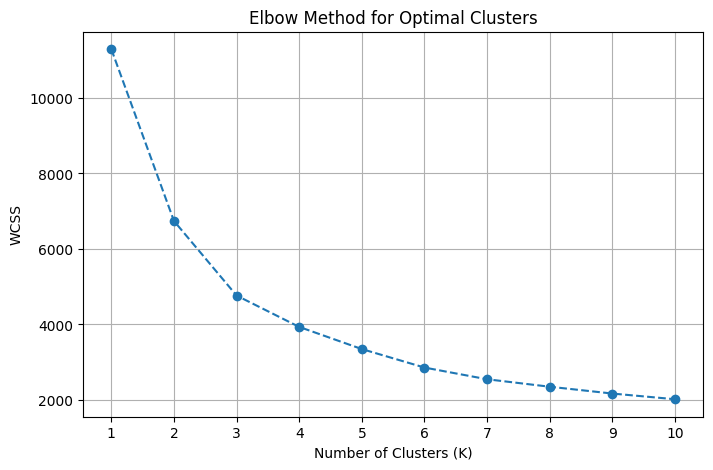

In [26]:
# Step 6: Determine optimal clusters using Elbow Method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print("\nWCSS Values:")
for k, value in enumerate(wcss, start=1):
    print("K =", k, " WCSS =", round(value, 2))


# Plot Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, 11),
    wcss,
    marker='o',
    linestyle='--'
)

plt.title("Elbow Method for Optimal Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

In [27]:
# Step 7: Apply K-Means with K = 3
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-Means Clustering Results:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nK-Means Silhouette Score:")
print(round(
    silhouette_score(X_scaled, df['KMeans_Cluster']),
    4
))


K-Means Clustering Results:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64

K-Means Silhouette Score:
0.3509


In [28]:
# Step 8: Display K-Means cluster centers
centers = scaler.inverse_transform(kmeans.cluster_centers_)

center_df = pd.DataFrame(
    centers,
    columns=features
)

print("\nK-Means Cluster Centers:")
print(center_df.round(2))


K-Means Cluster Centers:
   QUANTITYORDERED  PRICEEACH    SALES    MSRP
0            35.21      59.55  2101.08   64.15
1            43.73      97.49  5722.35  127.95
2            27.61      95.43  3123.73  113.23


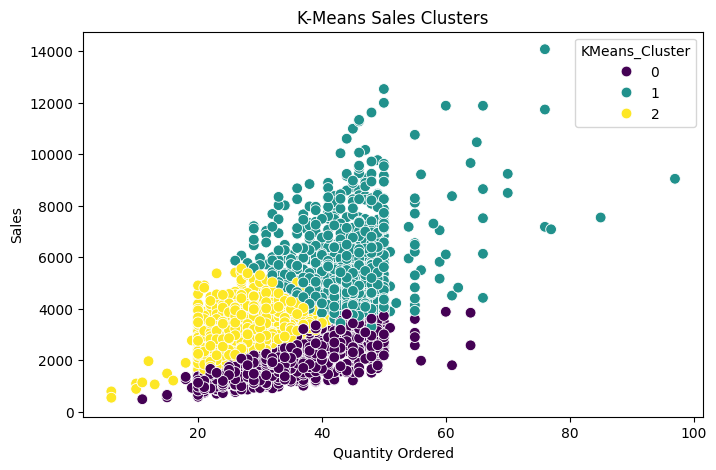

In [29]:
# Step 9: Visualize K-Means clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df['QUANTITYORDERED'],
    y=df['SALES'],
    hue=df['KMeans_Cluster'],
    palette='viridis',
    s=60
)

plt.title("K-Means Sales Clusters")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

In [30]:
# Step 10: Apply Hierarchical Clustering
hierarchical = AgglomerativeClustering(
    n_clusters=3,
    linkage='ward'
)

df['Hierarchical_Cluster'] = hierarchical.fit_predict(
    X_scaled
)

print("\nHierarchical Clustering Results:")
print(
    df['Hierarchical_Cluster']
    .value_counts()
    .sort_index()
)


Hierarchical Clustering Results:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


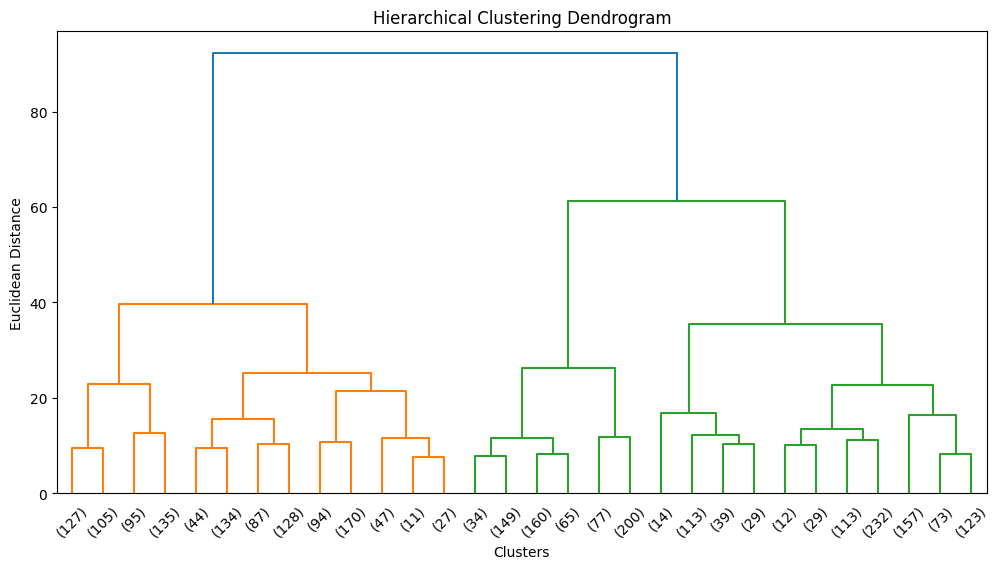

In [31]:
# Step 11: Draw Dendrogram
linked = linkage(
    X_scaled,
    method='ward'
)

plt.figure(figsize=(12, 6))

dendrogram(
    linked,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Clusters")
plt.ylabel("Euclidean Distance")
plt.show()

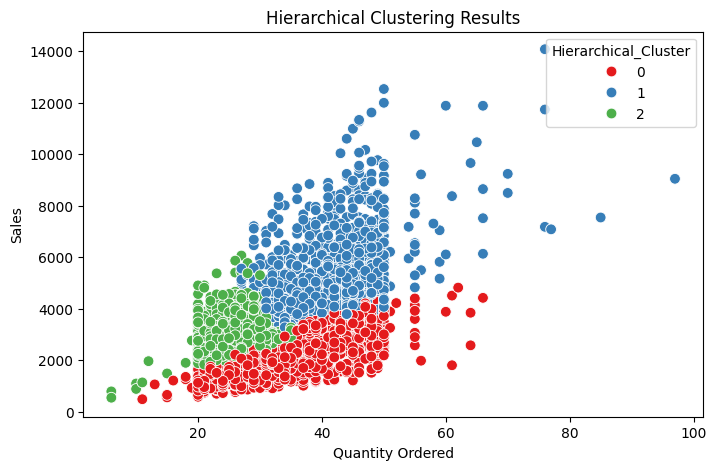

In [32]:
# Step 12: Visualize Hierarchical Clusters
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=df['QUANTITYORDERED'],
    y=df['SALES'],
    hue=df['Hierarchical_Cluster'],
    palette='Set1',
    s=60
)

plt.title("Hierarchical Clustering Results")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.show()

In [33]:
# Step 13: Compare cluster sizes
print("\n========== CLUSTER COMPARISON ==========")

print("\nK-Means Cluster Sizes:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nHierarchical Cluster Sizes:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())


========== CLUSTER COMPARISON ==========

K-Means Cluster Sizes:
KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64

Hierarchical Cluster Sizes:
Hierarchical_Cluster
0    1204
1     934
2     685
Name: count, dtype: int64


In [34]:
# Step 14: Cluster-wise sales analysis
print("\nK-Means Cluster Summary:")
print(
    df.groupby('KMeans_Cluster')[features]
    .mean()
    .round(2)
)

print("\nHierarchical Cluster Summary:")
print(
    df.groupby('Hierarchical_Cluster')[features]
    .mean()
    .round(2)
)


K-Means Cluster Summary:
                QUANTITYORDERED  PRICEEACH    SALES    MSRP
KMeans_Cluster                                             
0                         35.21      59.55  2101.08   64.15
1                         43.72      97.48  5720.08  127.89
2                         27.60      95.44  3123.06  113.27

Hierarchical Cluster Summary:
                      QUANTITYORDERED  PRICEEACH    SALES    MSRP
Hierarchical_Cluster                                             
0                               35.48      63.75  2273.01   70.55
1                               41.71      99.29  5575.63  127.05
2                               25.39      97.35  3048.60  117.84


In [20]:
# Step 15: Save results
df.to_csv("sales_clustering_results.csv", index=False)

print("\nClustering results saved successfully!")


Clustering results saved successfully!
